# Lab: uma chave de identificação para pinguins

Notebook de aula da página: https://insper.github.io/ML/pt/2026.2/classes/decision-trees/

Rode as células em ordem. Em cada passo, responda o **Preveja** com a dupla *antes* de rodar. Nas **Simulações**, escreva o experimento na célula vazia; as soluções e a leitura de cada resultado estão na página da aula.

## Passo 1 — carregar e olhar

**Preveja.** São três espécies de pinguins. Você espera que elas apareçam em proporções parecidas? Que acurácia teria um modelo que sempre responde a espécie mais comum?

In [1]:
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_openml

peng = fetch_openml(data_id=42585, as_frame=True).frame      # Palmer penguins
print(peng.shape)
print(peng['species'].value_counts().to_dict())
print(peng.isna().sum().to_dict())
print(peng['sex'].value_counts(dropna=False).to_dict())

(344, 7)
{'Adelie': 152, 'Gentoo': 124, 'Chinstrap': 68}
{'species': 0, 'island': 0, 'culmen_length_mm': 2, 'culmen_depth_mm': 2, 'flipper_length_mm': 2, 'body_mass_g': 2, 'sex': 10}
{'MALE': 168, 'FEMALE': 165, nan: 10, '_': 1}


**Resposta.** Não: são 152 Adelie, 124 Gentoo e só 68 Chinstrap, em 344 aves. Um modelo que sempre responde Adelie acerta 152/344 ≈ 44%, que é o piso a bater.

## Passo 2 — limpar e codificar

**Preveja.** A árvore aceita `NaN` e não precisa de escalonamento. Das três limpezas de costume — imputar, escalonar, codificar categorias —, qual ainda é necessária aqui?

In [2]:
num = ['culmen_length_mm', 'culmen_depth_mm', 'flipper_length_mm', 'body_mass_g']
peng = peng.dropna(subset=num)                    # as 2 aves sem medida nenhuma
X = peng[num].copy()
X['is_male'] = peng['sex'].astype(object).map({'MALE': 1.0, 'FEMALE': 0.0})   # '_' e desconhecido -> NaN
X = X.join(pd.get_dummies(peng['island'], prefix='island', dtype=float))      # one-hot
y = peng['species'].astype(str)
print(X.shape)
print("missing:", X.isna().sum()[X.isna().sum() > 0].to_dict())
print(X.head(3).to_string())

(342, 8)
missing: {'is_male': 9}
   culmen_length_mm  culmen_depth_mm  flipper_length_mm  body_mass_g  is_male  island_Biscoe  island_Dream  island_Torgersen
0              39.1             18.7              181.0       3750.0      1.0            0.0           0.0               1.0
1              39.5             17.4              186.0       3800.0      0.0            0.0           0.0               1.0
2              40.3             18.0              195.0       3250.0      0.0            0.0           0.0               1.0


**Resposta.** Só a codificação de categorias continua necessária: a ilha vira três colunas one-hot e o sexo vira `is_male`. Os 9 sexos desconhecidos ficam como `NaN`, que a árvore aceita, e nada é escalonado.

## Passo 3 — trancar o conjunto de teste e um baseline

**Preveja.** Com 86 pinguins no teste, quanto vale um único erro em pontos de acurácia? Isso muda o quanto você deve confiar na terceira casa decimal?

In [3]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
print(X_train.shape, X_test.shape)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


def cv_report(model):
    r = cross_validate(model, X_train, y_train, cv=cv, return_train_score=True)
    return (f"train {r['train_score'].mean():.3f} · validation "
            f"{r['test_score'].mean():.3f} ± {r['test_score'].std():.3f}")


print("dummy:", cv_report(DummyClassifier(strategy='most_frequent')))

(256, 8) (86, 8)
dummy: train 0.441 · validation 0.441 ± 0.009


**Resposta.** Um erro em 86 vale 1/86 ≈ 1,2 ponto de acurácia, então o teste só anda em degraus de 0,012 e a terceira casa decimal não merece confiança. O baseline fica em 0,441 na validação.

## Passo 4 — uma árvore de profundidade 2, lida como regras

**Preveja.** Uma única pergunta (profundidade 1) consegue separar três espécies? E, com duas perguntas em sequência, que medida você acha que a raiz vai usar?

depth 1: train 0.785 · validation 0.770 ± 0.034
depth 2: train 0.960 · validation 0.938 ± 0.040
['Adelie' 'Chinstrap' 'Gentoo']
|--- flipper_length_mm <= 206.50
|   |--- culmen_length_mm <= 43.35
|   |   |--- weights: [107.00, 4.00, 0.00] class: Adelie
|   |--- culmen_length_mm >  43.35
|   |   |--- weights: [4.00, 42.00, 1.00] class: Chinstrap
|--- flipper_length_mm >  206.50
|   |--- culmen_depth_mm <= 17.55
|   |   |--- weights: [0.00, 0.00, 91.00] class: Gentoo
|   |--- culmen_depth_mm >  17.55
|   |   |--- weights: [2.00, 5.00, 0.00] class: Chinstrap



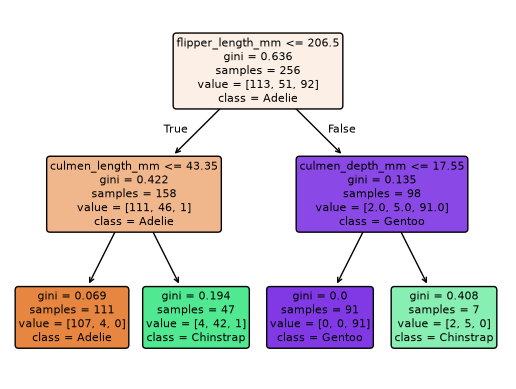

In [4]:
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

print("depth 1:", cv_report(DecisionTreeClassifier(max_depth=1, random_state=0)))
print("depth 2:", cv_report(DecisionTreeClassifier(max_depth=2, random_state=0)))

tree2 = DecisionTreeClassifier(max_depth=2, random_state=0).fit(X_train, y_train)
print(tree2.classes_)
print(export_text(tree2, feature_names=list(X.columns), show_weights=True))

plot_tree(tree2, feature_names=list(X.columns), class_names=list(tree2.classes_),
          filled=True, rounded=True, fontsize=8)
plt.show()

**Resposta.** Não: uma pergunta só divide em dois grupos, e a profundidade 1 fica em 0,770 na validação. Com duas perguntas sobe para 0,938, e a raiz é `flipper_length_mm <= 206.5`, que separa os Gentoo (nadadeira longa) das outras duas espécies.

**Simulação: a raiz, escolhida por você.** A seção 3 pontuou à mão todos os cortes de uma tabela de 12 clientes. Faça o mesmo com os pinguins: para cada uma das quatro medidas, teste todos os pontos médios entre valores vizinhos em `X_train`, pontue cada corte pelo Gini ponderado (agora com três classes) e guarde o melhor. A pergunta vencedora é a raiz que a árvore do passo 4 escolheu? Por quanto ela vence?

In [5]:
def gini(labels):
    p = labels.value_counts(normalize=True)
    return 1 - (p ** 2).sum()


rows = []
for col in num:
    x, lab = X_train[col], y_train
    values = np.unique(x)
    cuts = (values[:-1] + values[1:]) / 2                     # pontos médios entre vizinhos
    scores = [(x <= c).mean() * gini(lab[x <= c]) + (x > c).mean() * gini(lab[x > c]) for c in cuts]
    k = int(np.argmin(scores))
    rows.append((col, len(cuts), cuts[k], scores[k]))
best = pd.DataFrame(rows, columns=['feature', 'cuts tested', 'best threshold', 'weighted gini'])
print(f"root gini {gini(y_train):.3f}")
print(best.sort_values('weighted gini').round(3).to_string(index=False))
print("tree2 root:", X.columns[tree2.tree_.feature[0]], "<=", round(tree2.tree_.threshold[0], 2))

root gini 0.636
          feature  cuts tested  best threshold  weighted gini
flipper_length_mm           51           206.5          0.312
 culmen_length_mm          144            42.3          0.324
  culmen_depth_mm           75            16.4          0.331
      body_mass_g           89          4525.0          0.400
tree2 root: flipper_length_mm <= 206.5


**Leitura.** A busca exaustiva concorda com a árvore: o melhor corte é `flipper_length_mm <= 206.5`, com Gini ponderado 0,312, partindo de 0,636 na raiz. A vitória é apertada: o comprimento do bico fica em 0,324 e a profundidade em 0,331, menos de 0,02 atrás, e a massa corporal fica bem atrás (0,400). Com uma diferença tão pequena, outra amostra poderia trocar a raiz, como o passo 10 confirma.

## Passo 5 — crescer até o fim

**Preveja.** Sem limite nenhum, a árvore chega a 100% de acurácia no treino? E na validação: ela vai piorar em relação à de profundidade 2, como no Spambase, ou melhorar?

In [6]:
full = DecisionTreeClassifier(random_state=0)
print("fully grown:", cv_report(full))
full.fit(X_train, y_train)
print(f"depth {full.get_depth()} · {full.get_n_leaves()} leaves for {len(X_train)} penguins")

fully grown: train 1.000 · validation 0.969 ± 0.016
depth 5 · 13 leaves for 256 penguins


**Resposta.** Sim, 1,000 no treino, com 13 folhas e profundidade 5. Ao contrário do Spambase, a validação melhora: 0,969 contra 0,938 da profundidade 2, porque as espécies são bem separáveis e há pouco ruído para decorar.

**Simulação: uma árvore decora até rótulos aleatórios.** Embaralhe as espécies de `y_train` — cada pinguim fica com a espécie de outro, sorteado — e repita a validação cruzada da árvore crescida até o fim. O que acontece com a acurácia de treino? E com a de validação? Compare também o número de folhas com o da árvore com os rótulos verdadeiros.

In [7]:
rng = np.random.default_rng(42)
y_shuffled = pd.Series(rng.permutation(y_train.to_numpy()), index=y_train.index)   # espécie de outro pinguim

r = cross_validate(DecisionTreeClassifier(random_state=0), X_train, y_shuffled, cv=cv, return_train_score=True)
print(f"shuffled labels: train {r['train_score'].mean():.3f} · validation "
      f"{r['test_score'].mean():.3f} ± {r['test_score'].std():.3f}")
print(f"most frequent class share (shuffled): {y_shuffled.value_counts(normalize=True).max():.3f}")

noise = DecisionTreeClassifier(random_state=0).fit(X_train, y_shuffled)
print(f"leaves: {noise.get_n_leaves()} with shuffled labels vs {full.get_n_leaves()} with true labels")

shuffled labels: train 1.000 · validation 0.422 ± 0.051
most frequent class share (shuffled): 0.441
leaves: 105 with shuffled labels vs 13 with true labels


**Leitura.** Com as espécies embaralhadas, a árvore ainda chega a 1,000 no treino, mas a validação cai para 0,422 ± 0,051, abaixo até do baseline de 0,441. Para decorar ruído ela precisa de 105 folhas, contra 13 com os rótulos verdadeiros. A acurácia de treino de uma árvore sem limite não diz nada; só a validação mostra que não há padrão.

**Para fechar a parte fundamental.** Em uma frase cada: (1) o que faz uma pergunta ser melhor que outra? (2) Por que uma árvore crescida até o fim chega a 100% de acurácia de treino, mesmo com rótulos aleatórios? (3) Como você leria em voz alta um caminho da raiz até uma folha da chave do passo 4?

**Resposta.**

1. Uma pergunta é melhor quando deixa os filhos mais puros, ou seja, com menor impureza ponderada (a nadadeira teve Gini 0,312 contra 0,400 da massa corporal).
2. Sem limite, a árvore continua dividindo até cada folha ter uma só classe, o que sempre é possível quando as linhas são distintas: com rótulos aleatórios ela precisou de 105 folhas, mas decorou tudo.
3. "Se a nadadeira mede até 206,5 mm e o bico tem até 43,35 mm de comprimento, é um Adelie": 107 dos 111 pinguins de treino que chegam a essa folha são Adelie.

## Sua vez (fundamental)

Para casa:

1. **Entropia.** Refaça o passo 4 com `criterion='entropy'`. A árvore de profundidade 2 escolhe as mesmas perguntas? E os mesmos limiares?
2. **O ganho de informação à mão.** Na tabela dos 12 clientes, calcule à mão a entropia dos dois filhos de `bill ≤ 82.5` e o ganho de informação do corte. Confira com o 0,476 da seção 3.
3. **Folhas mínimas em vez de profundidade.** Refaça o passo 5 com `min_samples_leaf=5` e com `min_samples_leaf=10`. Quantas folhas a árvore tem e o que acontece com a acurácia de treino e com a de validação?

## Passo 6 — ajustar profundidade, tamanho de folha e poda juntos

**Preveja.** Numa grade de 96 configurações, você espera um vencedor isolado ou várias configurações empatadas dentro do ruído dos folds? Qual delas caberia num cartão?

In [8]:
from sklearn.model_selection import GridSearchCV

grid = {'max_depth': [1, 2, 3, 4, 5, None],
        'min_samples_leaf': [1, 2, 5, 10],
        'ccp_alpha': [0, 0.01, 0.02, 0.05]}
search = GridSearchCV(DecisionTreeClassifier(random_state=0), grid, cv=cv)
search.fit(X_train, y_train)

res = pd.DataFrame(search.cv_results_['params'])
res['validation'] = search.cv_results_['mean_test_score']
res['std'] = search.cv_results_['std_test_score']
res['leaves'] = [DecisionTreeClassifier(random_state=0, **p).fit(X_train, y_train).get_n_leaves()
                 for p in search.cv_results_['params']]
print(f"{len(res)} configurations · best {search.best_params_} · {search.best_score_:.3f}")

sd = res.loc[search.best_index_, 'std']                   # desvio padrão entre folds do melhor
close = res[res['validation'] >= search.best_score_ - sd]
print(f"within one std ({sd:.3f}) of the best: {len(close)} configurations")
print(close.sort_values(['leaves', 'validation'], ascending=[True, False]).head(6).round(3).to_string())

96 configurations · best {'ccp_alpha': 0, 'max_depth': 4, 'min_samples_leaf': 1} · 0.969
within one std (0.009) of the best: 14 configurations
    ccp_alpha  max_depth  min_samples_leaf  validation    std  leaves
32       0.01        3.0                 1       0.961  0.025       6
33       0.01        3.0                 2       0.961  0.025       6
9        0.00        3.0                 2       0.961  0.025       7
36       0.01        4.0                 1       0.961  0.025       8
37       0.01        4.0                 2       0.961  0.025       8
40       0.01        5.0                 1       0.961  0.025       8


**Resposta.** Várias empatadas: 14 configurações ficam a menos de um desvio padrão (0,009) da melhor (0,969). A que cabe num cartão é profundidade 3 com `ccp_alpha=0.01`: 6 folhas e 0,961 na validação.

## Passo 7 — os rivais, nos mesmos folds

**Preveja.** A regressão logística traça fronteiras retas em qualquer direção; a árvore, só degraus paralelos aos eixos. Sabendo que Adelie e Chinstrap diferem sobretudo na razão entre o comprimento e a profundidade do bico, quem você espera que vença?

In [9]:
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

chosen = close.sort_values(['leaves', 'validation'], ascending=[True, False]).iloc[0]
params = {'max_depth': None if pd.isna(chosen['max_depth']) else int(chosen['max_depth']),
          'min_samples_leaf': int(chosen['min_samples_leaf']), 'ccp_alpha': float(chosen['ccp_alpha'])}
key = DecisionTreeClassifier(random_state=0, **params)
print("chosen tree:", params)

prep = lambda: [SimpleImputer(strategy='most_frequent'), StandardScaler()]   # estes modelos precisam dos dois
rivals = {
    'logistic': GridSearchCV(make_pipeline(*prep(), LogisticRegression(max_iter=5000)),
                             {'logisticregression__C': [0.01, 0.1, 1, 10, 100]}, cv=cv),
    'k-NN': GridSearchCV(make_pipeline(*prep(), KNeighborsClassifier()),
                         {'kneighborsclassifier__n_neighbors': [1, 3, 5, 9, 15, 25]}, cv=cv),
}
folds = pd.DataFrame({'tree': cross_validate(key, X_train, y_train, cv=cv)['test_score']})
for name, s in rivals.items():
    s.fit(X_train, y_train)
    print(f"{name}: {s.best_params_}")
    folds[name] = [s.cv_results_[f'split{k}_test_score'][s.best_index_] for k in range(5)]
folds['logistic - tree'] = folds['logistic'] - folds['tree']
folds['k-NN - tree'] = folds['k-NN'] - folds['tree']
print(folds.round(3).to_string())
print(pd.DataFrame({'mean': folds.mean(), 'std': folds.std(ddof=0)}).T.round(3).to_string())

chosen tree: {'max_depth': 3, 'min_samples_leaf': 1, 'ccp_alpha': 0.01}


logistic: {'logisticregression__C': 1}


k-NN: {'kneighborsclassifier__n_neighbors': 1}
    tree  logistic   k-NN  logistic - tree  k-NN - tree
0  0.981      1.00  0.981            0.019        0.000
1  0.922      0.98  1.000            0.059        0.078
2  0.980      1.00  0.980            0.020        0.000
3  0.941      0.98  1.000            0.039        0.059
4  0.980      1.00  1.000            0.020        0.020
       tree  logistic   k-NN  logistic - tree  k-NN - tree
mean  0.961     0.992  0.992            0.031        0.031
std   0.025     0.010  0.010            0.016        0.032


**Resposta.** A regressão logística vence: 0,992 contra 0,961, com diferença de +0,031 ± 0,016 e positiva nos cinco folds. O k-NN empata com a logística na média (0,992), mas sua vantagem sobre a árvore oscila mais (± 0,032, zero em dois folds).

**Simulação: dê a diagonal à árvore.** O passo 7 atribuiu a derrota da chave a uma fronteira diagonal entre Adelie e Chinstrap. Teste a explicação: acrescente a razão `culmen_length_mm / culmen_depth_mm` como coluna e refaça a validação cruzada da mesma receita (profundidade 3, `ccp_alpha=0.01`). A acurácia sobe? A razão vira a raiz? Quantas folhas a chave precisa agora?

In [10]:
X_ratio = X_train.assign(culmen_ratio=X_train['culmen_length_mm'] / X_train['culmen_depth_mm'])
recipe = DecisionTreeClassifier(random_state=0, **params)       # a mesma receita da chave
print("recipe:", params)

r = cross_validate(recipe, X_ratio, y_train, cv=cv)
print(f"without ratio: {cross_validate(recipe, X_train, y_train, cv=cv)['test_score'].mean():.3f}")
print(f"with ratio:    {r['test_score'].mean():.3f} ± {r['test_score'].std():.3f}")

ratio_key = DecisionTreeClassifier(random_state=0, **params).fit(X_ratio, y_train)
print(f"root: {X_ratio.columns[ratio_key.tree_.feature[0]]} · {ratio_key.get_n_leaves()} leaves "
      f"(the key without the ratio has {key.fit(X_train, y_train).get_n_leaves()})")
print(export_text(ratio_key, feature_names=list(X_ratio.columns), show_weights=True))

recipe: {'max_depth': 3, 'min_samples_leaf': 1, 'ccp_alpha': 0.01}
without ratio: 0.961
with ratio:    0.973 ± 0.020
root: culmen_ratio · 5 leaves (the key without the ratio has 6)
|--- culmen_ratio <= 2.45
|   |--- culmen_length_mm <= 43.35
|   |   |--- weights: [108.00, 0.00, 0.00] class: Adelie
|   |--- culmen_length_mm >  43.35
|   |   |--- is_male <= 0.50
|   |   |   |--- weights: [0.00, 4.00, 0.00] class: Chinstrap
|   |   |--- is_male >  0.50
|   |   |   |--- weights: [5.00, 0.00, 0.00] class: Adelie
|--- culmen_ratio >  2.45
|   |--- island_Biscoe <= 0.50
|   |   |--- weights: [0.00, 47.00, 0.00] class: Chinstrap
|   |--- island_Biscoe >  0.50
|   |   |--- weights: [0.00, 0.00, 92.00] class: Gentoo



**Leitura.** A explicação se confirma: com a razão, a mesma receita sobe de 0,961 para 0,973 ± 0,020 na validação. A razão `culmen_ratio <= 2.45` vira a raiz e a chave cai de 6 para 5 folhas, separando de cara Adelie (bico curto e alto) de Chinstrap e Gentoo. Um único atributo bem construído substitui a escada de cortes paralelos aos eixos.

## Passo 8 — o único teste

**Preveja.** A validação cruzada deu 0,961 ± 0,025 para a chave. No teste, você espera um resultado parecido? Que par de espécies deve concentrar os erros?

In [11]:
from sklearn.metrics import confusion_matrix

key.fit(X_train, y_train)
pred = key.predict(X_test)
print(f"test accuracy {np.mean(pred == y_test):.3f} · misidentified: {np.sum(pred != y_test)} of {len(y_test)}")
print(pd.DataFrame(confusion_matrix(y_test, pred), index=key.classes_, columns=key.classes_))

test accuracy 0.988 · misidentified: 1 of 86
           Adelie  Chinstrap  Gentoo
Adelie         38          0       0
Chinstrap       1         16       0
Gentoo          0          0      31


**Resposta.** Parecido, e até melhor: 0,988 no teste, com um único erro em 86, dentro da faixa 0,961 ± 0,025 da validação. O erro é um Chinstrap tomado por Adelie, o par que a fronteira diagonal separa mal.

## Passo 9 — a chave e o que ela usa

**Preveja.** Das 8 colunas, quais você espera ver na chave? Alguma delas pode estar ali por um motivo que não tem nada a ver com biologia?

In [12]:
print(export_text(key, feature_names=list(X.columns), show_weights=True))
imp = pd.Series(key.feature_importances_, index=X.columns)
print(imp[imp > 0].sort_values(ascending=False).round(3).to_string())

|--- flipper_length_mm <= 206.50
|   |--- culmen_length_mm <= 43.35
|   |   |--- weights: [107.00, 4.00, 0.00] class: Adelie
|   |--- culmen_length_mm >  43.35
|   |   |--- island_Dream <= 0.50
|   |   |   |--- weights: [3.00, 0.00, 1.00] class: Adelie
|   |   |--- island_Dream >  0.50
|   |   |   |--- weights: [1.00, 42.00, 0.00] class: Chinstrap
|--- flipper_length_mm >  206.50
|   |--- culmen_depth_mm <= 17.55
|   |   |--- weights: [0.00, 0.00, 91.00] class: Gentoo
|   |--- culmen_depth_mm >  17.55
|   |   |--- culmen_depth_mm <= 18.95
|   |   |   |--- weights: [2.00, 0.00, 0.00] class: Adelie
|   |   |--- culmen_depth_mm >  18.95
|   |   |   |--- weights: [0.00, 5.00, 0.00] class: Chinstrap

flipper_length_mm    0.548
culmen_length_mm     0.328
culmen_depth_mm      0.087
island_Dream         0.037


**Resposta.** A chave usa nadadeira (0,548), comprimento do bico (0,328), profundidade do bico (0,087) e `island_Dream` (0,037). A ilha está ali por amostragem, não por biologia: nestes dados quase todo Chinstrap foi medido em Dream, e a chave usa isso para separá-lo dos Adelie.

## Passo 10 — quão estável é a chave?

**Preveja.** Se outra equipe medisse pinguins parecidos e rodasse a mesma receita, a chave começaria pela mesma pergunta? E as previsões, mudariam tanto quanto as perguntas?

In [13]:
rng = np.random.default_rng(0)
roots, preds = [], []
for b in range(100):
    idx = rng.integers(0, len(X_train), len(X_train))             # reamostra bootstrap
    m = DecisionTreeClassifier(random_state=0, **params).fit(X_train.iloc[idx], y_train.iloc[idx])
    roots.append((X.columns[m.tree_.feature[0]], round(m.tree_.threshold[0], 2)))
    preds.append(m.predict(X_test))
roots = pd.DataFrame(roots, columns=['feature', 'threshold'])
print(roots.groupby('feature')['threshold'].agg(['count', 'min', 'max']))
preds = np.array(preds)
disagree = np.mean([np.mean(preds[i] != preds[j]) for i in range(100) for j in range(i + 1, 100)])
print(f"two resampled keys disagree on {disagree:.1%} of the test penguins")
print(f"test penguins on which all 100 keys agree: {np.mean((preds == preds[0]).all(axis=0)):.1%}")

                   count     min     max
feature                                 
culmen_depth_mm       12   16.05   16.40
culmen_length_mm      32   41.55   43.35
flipper_length_mm     56  202.50  207.50


two resampled keys disagree on 4.1% of the test penguins


test penguins on which all 100 keys agree: 73.3%


**Resposta.** Não necessariamente: em 100 reamostras a raiz foi a nadadeira 56 vezes, o comprimento do bico 32 e a profundidade 12, com limiares que também variam. As previsões mudam bem menos: duas chaves discordam em 4,1% dos pinguins do teste, e as 100 concordam em 73,3% deles.

**Simulação: bagging à mão.** O passo 10 mostrou que chaves treinadas em reamostras diferentes discordam. Use isso a seu favor: dentro de cada fold do `cv`, ajuste 100 árvores crescidas até o fim, cada uma numa reamostra bootstrap do treino do fold, e deixe-as votar (a espécie mais frequente entre as 100 previsões). Compare com uma única árvore crescida até o fim, nos mesmos folds.

In [14]:
rng = np.random.default_rng(42)
rows = []
for k, (tr, va) in enumerate(cv.split(X_train, y_train)):
    Xf, yf = X_train.iloc[tr], y_train.iloc[tr]
    Xv, yv = X_train.iloc[va], y_train.iloc[va].to_numpy()
    votes = []
    for b in range(100):
        idx = rng.integers(0, len(Xf), len(Xf))                # reamostra bootstrap do treino do fold
        votes.append(DecisionTreeClassifier(random_state=0).fit(Xf.iloc[idx], yf.iloc[idx]).predict(Xv))
    votes = np.array(votes)
    vote = pd.DataFrame(votes).mode().iloc[0].to_numpy()       # espécie mais votada em cada pinguim
    single = DecisionTreeClassifier(random_state=0).fit(Xf, yf).predict(Xv)
    rows.append({'one tree': np.mean(single == yv),
                 'avg bootstrap tree': np.mean(votes == yv),
                 'vote of 100': np.mean(vote == yv)})
bag = pd.DataFrame(rows)
bag['vote - one tree'] = bag['vote of 100'] - bag['one tree']
print(bag.round(3).to_string())
print(pd.DataFrame({'mean': bag.mean(), 'std': bag.std(ddof=0)}).T.round(3).to_string())

   one tree  avg bootstrap tree  vote of 100  vote - one tree
0     0.981               0.959        0.981            0.000
1     0.961               0.928        1.000            0.039
2     0.980               0.960        0.980            0.000
3     0.941               0.940        0.961            0.020
4     0.980               0.967        0.980            0.000
      one tree  avg bootstrap tree  vote of 100  vote - one tree
mean     0.969               0.951        0.980            0.012
std      0.016               0.014        0.012            0.016


**Leitura.** O voto de 100 árvores chega a 0,980 ± 0,012, contra 0,969 ± 0,016 de uma árvore crescida até o fim; ele nunca perde nos 5 folds e ganha em dois. Cada árvore bootstrap sozinha é pior (0,951 em média), porque vê só cerca de 63% das linhas distintas, mas seus erros caem em pinguins diferentes e o voto os cancela. A vantagem é pequena aqui, porque a árvore única já erra pouco.

**Para fechar a aula.** Em uma frase cada: (1) por que a chave perdeu para a regressão logística e o que a recuperou em parte? (2) Por que chaves treinadas em reamostras diferentes começam por perguntas diferentes? (3) Por que o voto de muitas árvores erra menos que uma árvore só?

**Resposta.**

1. A fronteira entre Adelie e Chinstrap é diagonal (a razão entre comprimento e profundidade do bico), que a logística traça direto e a árvore só aproxima com degraus; dar a razão como coluna levou a chave de 0,961 para 0,973.
2. Os melhores cortes têm pontuações muito próximas (0,312, 0,324 e 0,331), então uma reamostra muda o vencedor da raiz, e como a árvore é gulosa, todo o resto da chave muda junto.
3. Árvores treinadas em reamostras diferentes erram em pinguins diferentes, e a maioria corrige os erros isolados: 0,951 por árvore bootstrap, 0,969 para a árvore única e 0,980 para o voto.

## Sua vez (avançado)

Para casa, com mais tempo:

1. **Entropia na grade.** Acrescente `'criterion': ['gini', 'entropy']` à grade do passo 6. Quantas das configurações a menos de um desvio padrão da melhor usam entropia? A chave escolhida muda?
2. **Uma árvore de regressão.** No CSV de imóveis da Califórnia (`pd.read_csv('https://raw.githubusercontent.com/hsandmann/biblio/refs/heads/main/ml/aula02/housing.csv')`), preveja `median_house_value` a partir das colunas numéricas com um `DecisionTreeRegressor`. Ajuste `max_depth` e `min_samples_leaf` com `KFold(5, shuffle=True, random_state=0)` e compare o RMSE da melhor árvore com o de uma `LinearRegression`. Qual é o maior valor que a árvore pode prever? Por quê?
3. **Importância por permutação.** Calcule `permutation_importance(key, X_test, y_test, n_repeats=30, random_state=0)` (de `sklearn.inspection`) e compare com as importâncias por impureza do passo 9. A ilha Dream continua importando? Algum atributo que a chave não usa ganha importância?

### Sua vez — exercício 1 (fundamental): entropia

In [15]:
print("gini, depth 2:   ", cv_report(DecisionTreeClassifier(max_depth=2, random_state=0)))
print("entropy, depth 2:", cv_report(DecisionTreeClassifier(max_depth=2, criterion='entropy', random_state=0)))

tree2_ent = DecisionTreeClassifier(max_depth=2, criterion='entropy', random_state=0).fit(X_train, y_train)
print(export_text(tree2_ent, feature_names=list(X.columns), show_weights=True))

gini, depth 2:    train 0.960 · validation 0.938 ± 0.040
entropy, depth 2: train 0.955 · validation 0.910 ± 0.040
|--- flipper_length_mm <= 206.50
|   |--- culmen_length_mm <= 42.30
|   |   |--- weights: [102.00, 1.00, 0.00] class: Adelie
|   |--- culmen_length_mm >  42.30
|   |   |--- weights: [9.00, 45.00, 1.00] class: Chinstrap
|--- flipper_length_mm >  206.50
|   |--- culmen_depth_mm <= 17.55
|   |   |--- weights: [0.00, 0.00, 91.00] class: Gentoo
|   |--- culmen_depth_mm >  17.55
|   |   |--- weights: [2.00, 5.00, 0.00] class: Chinstrap



**Conclusão.** As mesmas perguntas: nadadeira `<= 206.5` na raiz, comprimento do bico à esquerda e profundidade do bico `<= 17.55` à direita. Só o limiar do comprimento do bico muda, de 43,35 para 42,30, o que manda 9 Adelie para a folha Chinstrap; a validação cai de 0,938 para 0,910 ± 0,040, uma diferença dentro do ruído dos folds.

### Sua vez — exercício 2 (fundamental): o ganho de informação à mão

In [16]:
customers = pd.DataFrame({'tenure': [2, 3, 5, 6, 8, 11, 14, 19, 24, 30, 38, 50],
                          'bill': [95, 120, 60, 110, 45, 130, 70, 115, 55, 125, 100, 65],
                          'churn': [1, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0]}, index=list('ABCDEFGHIJKL'))


def entropy(labels):
    p = labels.value_counts(normalize=True)
    return 0.0 - (p * np.log2(p)).sum()          # 0.0 - evita imprimir -0.000


left = customers.loc[customers['bill'] <= 82.5, 'churn']
right = customers.loc[customers['bill'] > 82.5, 'churn']
h_root, h_left, h_right = entropy(customers['churn']), entropy(left), entropy(right)
gain = h_root - len(left) / 12 * h_left - len(right) / 12 * h_right
print(f"root: {customers['churn'].value_counts().to_dict()} · entropy {h_root:.3f}")
print(f"left  (bill <= 82.5): {left.value_counts().to_dict()} · entropy {h_left:.3f}")
print(f"right (bill >  82.5): {right.value_counts().to_dict()} · entropy {h_right:.3f}")
print(f"information gain {h_root:.3f} - {len(left)}/12·{h_left:.3f} - {len(right)}/12·{h_right:.3f} = {gain:.3f}")

root: {0: 7, 1: 5} · entropy 0.980
left  (bill <= 82.5): {0: 5} · entropy 0.000
right (bill >  82.5): {1: 5, 0: 2} · entropy 0.863
information gain 0.980 - 5/12·0.000 - 7/12·0.863 = 0.476


**Conclusão.** O filho esquerdo (`bill <= 82.5`) tem 5 clientes que ficaram e nenhum que cancelou, com entropia 0. O direito tem 2 que ficaram e 5 que cancelaram, com entropia 0,863. O ganho é 0,980 − 5/12·0 − 7/12·0,863 = 0,476, igual ao da seção 3.

### Sua vez — exercício 3 (fundamental): folhas mínimas em vez de profundidade

In [17]:
for leaf in [1, 5, 10]:
    m = DecisionTreeClassifier(min_samples_leaf=leaf, random_state=0)
    n_leaves = m.fit(X_train, y_train).get_n_leaves()
    print(f"min_samples_leaf={leaf:2d}: {n_leaves:2d} leaves · {cv_report(m)}")

min_samples_leaf= 1: 13 leaves · train 1.000 · validation 0.969 ± 0.016
min_samples_leaf= 5:  8 leaves · train 0.957 · validation 0.930 ± 0.052


min_samples_leaf=10:  7 leaves · train 0.946 · validation 0.926 ± 0.047


**Conclusão.** A árvore encolhe de 13 folhas para 8 (`min_samples_leaf=5`) e 7 (`min_samples_leaf=10`), e a acurácia de treino cai de 1,000 para 0,957 e 0,946. A validação também cai, de 0,969 para 0,930 e 0,926, com desvios maiores (± 0,05): nos pinguins a árvore completa quase não superajusta, e exigir folhas grandes impede de isolar grupos pequenos, como os 5 Chinstrap de nadadeira longa que a chave separa no passo 9.

### Sua vez — exercício 1 (avançado): entropia na grade

In [18]:
search_ent = GridSearchCV(DecisionTreeClassifier(random_state=0), {**grid, 'criterion': ['gini', 'entropy']}, cv=cv)
search_ent.fit(X_train, y_train)

res_ent = pd.DataFrame(search_ent.cv_results_['params'])
res_ent['validation'] = search_ent.cv_results_['mean_test_score']
res_ent['std'] = search_ent.cv_results_['std_test_score']
res_ent['leaves'] = [DecisionTreeClassifier(random_state=0, **p).fit(X_train, y_train).get_n_leaves()
                     for p in search_ent.cv_results_['params']]
print(f"{len(res_ent)} configurations · best {search_ent.best_params_} · {search_ent.best_score_:.3f}")

sd_ent = res_ent.loc[search_ent.best_index_, 'std']
close_ent = res_ent[res_ent['validation'] >= search_ent.best_score_ - sd_ent]
print(f"within one std ({sd_ent:.3f}) of the best: {len(close_ent)} configurations · "
      f"{close_ent['criterion'].value_counts().to_dict()}")
print(close_ent.sort_values(['leaves', 'validation'], ascending=[True, False]).head(6).round(3).to_string())

192 configurations · best {'ccp_alpha': 0, 'criterion': 'gini', 'max_depth': 4, 'min_samples_leaf': 1} · 0.969
within one std (0.009) of the best: 24 configurations · {'gini': 14, 'entropy': 10}
     ccp_alpha criterion  max_depth  min_samples_leaf  validation    std  leaves
56        0.01      gini        3.0                 1       0.961  0.025       6
57        0.01      gini        3.0                 2       0.961  0.025       6
132       0.02   entropy        4.0                 1       0.961  0.017       7
133       0.02   entropy        4.0                 2       0.961  0.017       7
9         0.00      gini        3.0                 2       0.961  0.025       7
85        0.01   entropy        4.0                 2       0.961  0.017       8


**Conclusão.** Das 192 configurações, 24 ficam a menos de um desvio padrão (0,009) da melhor, e 10 delas usam entropia. A melhor continua sendo Gini com profundidade 4 (0,969), e a chave escolhida pelo menor número de folhas não muda: Gini, profundidade 3, `ccp_alpha=0.01`, 6 folhas. A versão mais simples com entropia precisa de 7 folhas para o mesmo 0,961.

### Sua vez — exercício 2 (avançado): uma árvore de regressão

In [19]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold
from sklearn.tree import DecisionTreeRegressor

housing = pd.read_csv('https://raw.githubusercontent.com/hsandmann/biblio/refs/heads/main/ml/aula02/housing.csv')
Xh = housing.drop(columns='median_house_value').select_dtypes('number')
yh = housing['median_house_value']
print(Xh.shape, "· missing:", Xh.isna().sum()[Xh.isna().sum() > 0].to_dict())

kf = KFold(5, shuffle=True, random_state=0)
tree_search = GridSearchCV(DecisionTreeRegressor(random_state=0),
                           {'max_depth': [4, 6, 8, 10, 12, 15, None], 'min_samples_leaf': [1, 5, 10, 20, 50]},
                           cv=kf, scoring='neg_root_mean_squared_error')
tree_search.fit(Xh, yh)
print(f"best tree {tree_search.best_params_} · RMSE {-tree_search.best_score_:,.0f}")

linear = make_pipeline(SimpleImputer(strategy='median'), LinearRegression())   # a regressão não aceita NaN
rmse_lin = -cross_validate(linear, Xh, yh, cv=kf, scoring='neg_root_mean_squared_error')['test_score']
print(f"linear regression · RMSE {rmse_lin.mean():,.0f}")

best_tree = tree_search.best_estimator_
print(f"largest value the tree can predict: {best_tree.tree_.value.max():,.0f} · largest target: {yh.max():,.0f}")
print(f"houses at the cap: {(yh == yh.max()).sum()} of {len(yh)}")

(20640, 8) · missing: {'total_bedrooms': 207}


best tree {'max_depth': None, 'min_samples_leaf': 20} · RMSE 58,320
linear regression · RMSE 69,791
largest value the tree can predict: 500,001 · largest target: 500,001
houses at the cap: 965 of 20640


**Conclusão.** A melhor árvore (`max_depth=None`, `min_samples_leaf=20`) tem RMSE de 58.320 dólares, contra 69.791 da regressão linear. O maior valor que ela pode prever é 500.001, exatamente o maior alvo. Cada folha prevê a média dos imóveis de treino que caem nela, então a árvore nunca extrapola além do maior valor visto, e esse máximo é o teto artificial do censo (965 imóveis estão nele).

### Sua vez — exercício 3 (avançado): importância por permutação

In [20]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(key, X_test, y_test, n_repeats=30, random_state=0)
cmp = pd.DataFrame({'impurity': key.feature_importances_, 'permutation': perm.importances_mean,
                    '± std': perm.importances_std}, index=X.columns)
print(cmp.sort_values('permutation', ascending=False).round(3).to_string())

                   impurity  permutation  ± std
flipper_length_mm     0.548        0.364  0.045
culmen_length_mm      0.328        0.162  0.029
culmen_depth_mm       0.087        0.150  0.025
island_Dream          0.037        0.120  0.020
body_mass_g           0.000        0.000  0.000
is_male               0.000        0.000  0.000
island_Biscoe         0.000        0.000  0.000
island_Torgersen      0.000        0.000  0.000


**Conclusão.** A ordem se mantém (nadadeira 0,364, comprimento do bico 0,162, profundidade 0,150), mas a ilha Dream sobe bastante: de 0,037 por impureza para 0,120 por permutação, porque embaralhá-la desvia muitos Chinstrap para o lado Adelie. Nenhum atributo fora da chave ganha importância: massa, sexo e as outras ilhas ficam em 0,000, já que a chave nunca os consulta.